# 02 — SNOMED-CT Multi-Label Taxonomy, CinC 2020 Audit & Label Conflicts

Georgia 12-Lead ECG uses multi-label **SNOMED-CT** diagnostic codes embedded in each `.hea` file (`# Dx:`). This notebook audits:

1. **Scored vs Unscored CinC 2020 Coverage**: Cross-checking all SNOMED-CT codes in Georgia against the official PhysioNet/CinC 2020 tables (`dx_mapping_scored.csv` [`27` classes] and `dx_mapping_unscored.csv` [`84` classes]), verifying our counts against the official `Georgia` benchmark column, and flagging unmapped or empty-`Dx` records.
2. **Multi-Label Cardinality & Co-occurrence**: Distribution of labels per ECG and co-occurrence heatmap across the top 14 scored CinC 2020 diagnoses (`NSR`, `AF`, `IAVB`, `LAD`, `SB`, `STach`, `TAb`, `TInv`, `LAnFB`, `RBBB`, `LBBB`, `LVH`, `PAC`, `PVC`).
3. **Label Contradiction Audit (`NSR` + Arrhythmia Collisions)**: Identifying records simultaneously tagged with `NSR` (`426783006`) and incompatible rhythms (`AF`, `AFL`, `SB`, `STach`, `SVT`, `PR`).
4. **Epidemiological Sanity**: Prevalence of major cardiac conditions across age decades × sex.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "georgia_ecg" / "quality" / "error_labels.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate georgia_ecg/quality/error_labels.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from georgia_ecg import GeorgiaECGDataset

GEORGIA_DIR = REPO_ROOT / "georgia_ecg"
DATA_DIR = GEORGIA_DIR / "data"
LEADS = GeorgiaECGDataset.LEADS

df = pd.read_csv(GEORGIA_DIR / "quality" / "error_labels.csv", index_col="record_id")
df["snomed_codes"] = df["snomed_codes"].fillna("")
df["label_names"] = df["label_names"].fillna("")
df["error_tags"] = df["error_tags"].fillna("")
df["sex"] = df["sex"].fillna("")
print(f"Loaded {len(df):,} Georgia 12-Lead ECG records from error_labels.csv")

scored_df = pd.read_csv(GEORGIA_DIR / "quality" / "dx_mapping_scored.csv")
unscored_df = pd.read_csv(GEORGIA_DIR / "quality" / "dx_mapping_unscored.csv")
scored_df.columns = scored_df.columns.str.strip()
unscored_df.columns = unscored_df.columns.str.strip()

code_to_abbr = {}
code_to_dx = {}
scored_set = set()
for mdf, is_sc in [(scored_df, True), (unscored_df, False)]:
    for c, abbr, name in zip(mdf["SNOMED CT Code"].astype(str), mdf["Abbreviation"].astype(str), mdf["Dx"].astype(str)):
        c = c.strip()
        code_to_abbr.setdefault(c, abbr.strip())
        code_to_dx.setdefault(c, name.strip())
        if is_sc:
            scored_set.add(c)

valid_df = df[df["err_file_missing_or_corrupt"] == 0].copy()
valid_df["code_list"] = valid_df["snomed_codes"].apply(lambda s: [x for x in s.split("|") if x])

# Count every SNOMED-CT code present in Georgia
from collections import Counter
code_counts = Counter(c for lst in valid_df["code_list"] for c in lst)

print(f"Distinct SNOMED-CT codes in Georgia       : {len(code_counts)}")
print(f"  In CinC 2020 Scored (27 classes)        : {sum(1 for c in code_counts if c in scored_set)}")
print(f"  In CinC 2020 Unscored                   : {sum(1 for c in code_counts if c in code_to_abbr and c not in scored_set)}")
print(f"  Unmapped (not in either CinC 2020 CSV)  : {sum(1 for c in code_counts if c not in code_to_abbr)}")
print(f"Records with ZERO Dx codes                : {int(valid_df['err_dx_empty'].sum())}")
print(f"Records with ZERO scored CinC 2020 codes  : {int(valid_df['err_dx_no_scored_cinc2020'].sum())}")
print(f"Records with NSR + Arrhythmia conflict    : {int(valid_df['err_dx_nsr_pathology_conflict'].sum())}")

# Compare observed counts against official CinC 2020 'Georgia' column
scored_audit = scored_df[["Abbreviation", "Dx", "SNOMED CT Code", "Georgia"]].copy()
scored_audit["Observed"] = scored_audit["SNOMED CT Code"].astype(str).map(lambda c: code_counts.get(c.strip(), 0))
scored_audit["Diff"] = scored_audit["Observed"] - scored_audit["Georgia"]
display(scored_audit.sort_values("Observed", ascending=False).head(15))

Loaded 10,344 Georgia 12-Lead ECG records from error_labels.csv
Distinct SNOMED-CT codes in Georgia       : 67
  In CinC 2020 Scored (27 classes)        : 24
  In CinC 2020 Unscored                   : 43
  Unmapped (not in either CinC 2020 CSV)  : 0
Records with ZERO Dx codes                : 0
Records with ZERO scored CinC 2020 codes  : 885
Records with NSR + Arrhythmia conflict    : 0


,Abbreviation,Dx,SNOMED CT Code,Georgia,Observed,Diff
24,TAb,t wave abnormal,164934002,2306,2303,-3
21,NSR,sinus rhythm,426783006,1752,1750,-2
20,SB,sinus bradycardia,426177001,1677,1676,-1
15,LQT,prolonged qt interval,111975006,1391,1388,-3
22,STach,sinus tachycardia,427084000,1261,1261,0
12,PAC,premature atrial contraction,284470004,639,1234,595
7,LAD,left axis deviation,39732003,940,939,-1
25,TInv,t wave inversion,59931005,812,811,-1
0,IAVB,1st degree av block,270492004,769,768,-1
1,AF,atrial fibrillation,164889003,570,570,0


Sample NSR + Arrhythmia Conflict Records (total=0):


,age,sex,label_names,est_hr_bpm
record_id,,,,


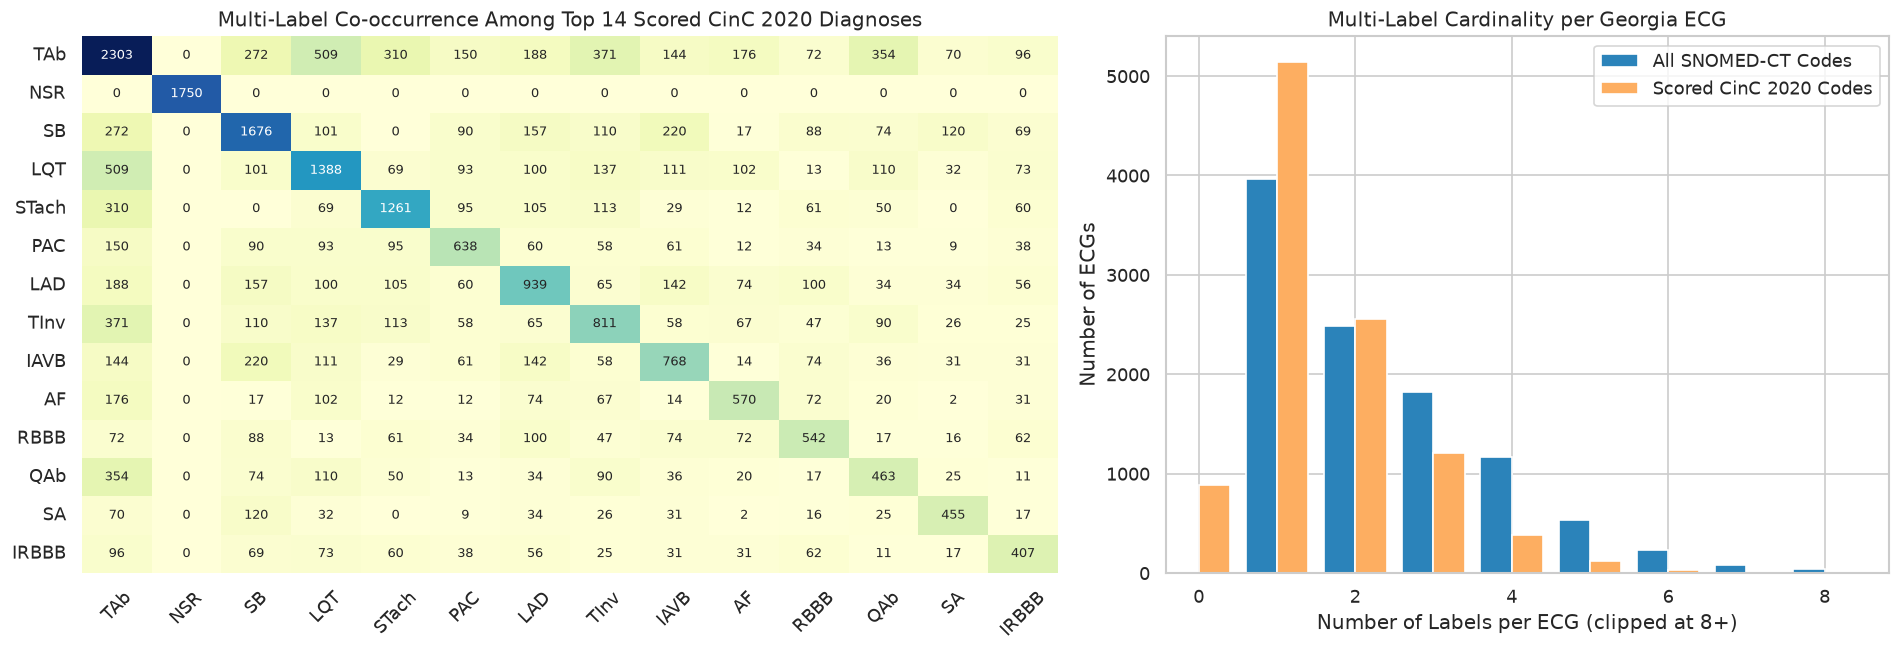

In [2]:
# Show NSR + conflicting rhythm records & top unscored codes
conflicts = valid_df[valid_df["err_dx_nsr_pathology_conflict"] == 1][["age", "sex", "label_names", "est_hr_bpm"]]
print(f"Sample NSR + Arrhythmia Conflict Records (total={len(conflicts)}):")
display(conflicts.head(10))

# Build co-occurrence matrix for top 14 scored CinC 2020 codes
top14 = scored_audit.sort_values("Observed", ascending=False).head(14)
top14_codes = top14["SNOMED CT Code"].astype(str).str.strip().tolist()
top14_abbrs = top14["Abbreviation"].str.strip().tolist()

cooc = pd.DataFrame(0, index=top14_abbrs, columns=top14_abbrs)
code_to_pos = {c: abbr for c, abbr in zip(top14_codes, top14_abbrs)}
for lst in valid_df["code_list"]:
    present = sorted({code_to_pos[c] for c in lst if c in code_to_pos})
    for a in present:
        for b in present:
            cooc.loc[a, b] += 1

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), gridspec_kw={"width_ratios": [1.35, 1]})

sns.heatmap(cooc, annot=True, fmt="d", cmap="YlGnBu", ax=axes[0], cbar=False, annot_kws={"size": 7.5})
axes[0].set_title("Multi-Label Co-occurrence Among Top 14 Scored CinC 2020 Diagnoses")
axes[0].tick_params(axis="x", rotation=45)

# Right: Label cardinality per ECG (total vs scored)
card_all = valid_df["n_dx_codes"].clip(upper=8).value_counts().sort_index()
card_sc  = valid_df["n_scored_codes"].clip(upper=8).value_counts().sort_index()
x = np.arange(len(card_all))
w = 0.4
axes[1].bar(card_all.index - w/2, card_all.values, width=w, label="All SNOMED-CT Codes", color="#2b83ba")
axes[1].bar(card_sc.index + w/2, card_sc.values, width=w, label="Scored CinC 2020 Codes", color="#fdae61")
axes[1].set_xlabel("Number of Labels per ECG (clipped at 8+)")
axes[1].set_ylabel("Number of ECGs")
axes[1].set_title("Multi-Label Cardinality per Georgia ECG")
axes[1].legend()

plt.tight_layout()
plt.show()

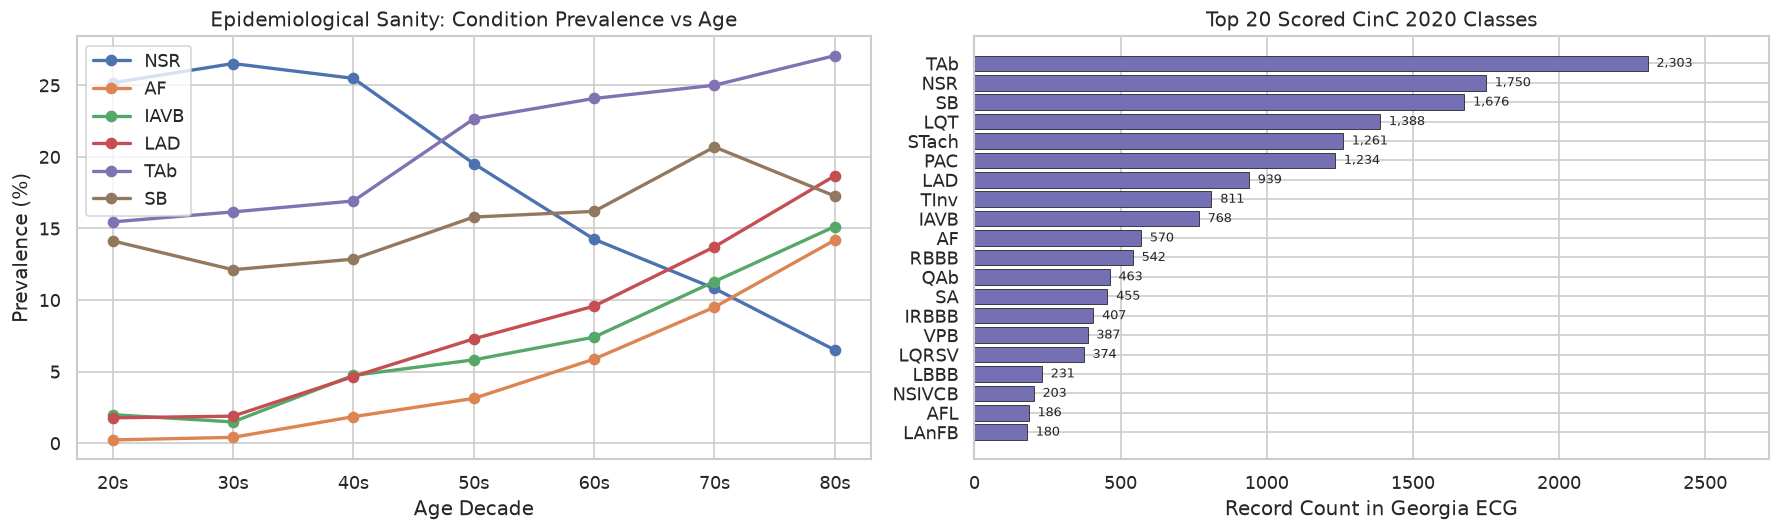

In [3]:
# Epidemiological sanity check: prevalence of key diagnoses across Age Decades
epi = valid_df[valid_df["age"].between(18, 90)].copy()
epi["age_decade"] = pd.cut(epi["age"], bins=[18, 30, 40, 50, 60, 70, 80, 90], labels=["20s", "30s", "40s", "50s", "60s", "70s", "80s"])

key_codes = {"NSR": "426783006", "AF": "164889003", "IAVB": "270492004", "LAD": "39732003", "TAb": "164934002", "SB": "426177001"}
epi_rates = pd.DataFrame({
    name: epi.groupby("age_decade", observed=False)["code_list"].apply(lambda s: s.apply(lambda l: code in l).mean() * 100)
    for name, code in key_codes.items()
})

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
epi_rates.plot(marker="o", lw=2, ax=axes[0])
axes[0].set_ylabel("Prevalence (%)")
axes[0].set_xlabel("Age Decade")
axes[0].set_title("Epidemiological Sanity: Condition Prevalence vs Age")

# Top 20 scored CinC 2020 classes bar chart
top20 = scored_audit.sort_values("Observed", ascending=True).tail(20)
axes[1].barh(top20["Abbreviation"], top20["Observed"], color="#7570b3", edgecolor="black", lw=0.4)
axes[1].set_xlabel("Record Count in Georgia ECG")
axes[1].set_title("Top 20 Scored CinC 2020 Classes")
for i, v in enumerate(top20["Observed"].values):
    axes[1].text(v + 30, i, f"{v:,}", va="center", fontsize=8)
axes[1].set_xlim(0, top20["Observed"].max() * 1.18)

plt.tight_layout()
plt.show()